# 🚀 TRAINING KATEGORI: DATA AUGMENTASI (250 SAMPEL) + SVM
### Melatih Model SVM Berdasarkan Bobot Baseline CLIP Murni Menggunakan Data Augmentasi

---

## 📌 1. Mengapa Melakukan Data Augmentasi Terlebih Dahulu?
Dengan hanya 50 data asli (10 per kategori), model klasifikasi mudah menghafal sudut pandang gambar tertentu (*overfitting*).  
Dengan menerapkan **4 variasi per gambar**:
$$\mathbf{50\ Gambar\ Asli} 	imes \mathbf{5\ (1\ Asli + 4\ Variasi)} = \mathbf{250\ Sampel\ Gambar}$$
Setiap kategori kini memiliki **50 sampel** yang kaya dengan variasi:
1. **Brightness & Contrast Jitter**: Menghadapi kondisi pencahayaan ruangan/kamar asrama yang terang maupun temaram.
2. **Random Rotation (±15°)**: Menghadapi posisi kemiringan kamera pengguna saat mengambil foto.
3. **Random Resized Crop (Scale 85% - 100%)**: Menghadapi objek foto yang tidak berada tepat di tengah (*zooming*).
4. **Horizontal Flip**: Membalik sudut simetri produk secara horizontal.

---

## ⚙️ 2. Konfigurasi Pelatihan (Hyperparameter Setup)
* **Model Ekstraktor**: `clip_model_weights` (Model Pre-trained Baseline Asli OpenAI, 100% murni tanpa distorsi).
* **Ukuran Fitur Masukan**: 512 dimensi ($L_2	ext{-normalized}$).
* **Arsitektur Pengklasifikasi**:
  1. **Dual-Model Classifier**:
     - **Metode A - Linear SVM (`CalibratedClassifierCV(SVC)`)**: Menemukan batas pemisah margin terluas (*Maximum Margin*) dengan bobot penyeimbang *balanced*.
     - **Metode B - Neural Linear Probe (PyTorch Linear Classifier)**: Dilatih menggunakan **Optimizer AdamW**, **Learning Rate 0.001**, **Weight Decay 0.01**, dan **25 Epoch**.
* **Pencegahan Overfitting**:
  - Backbone CLIP **terkunci penuh (*freeze*)**.
  - Dilengkapi L2-Regularization (Weight Decay) dan Cross-Validation berbasis *Stratified Group/K-Fold*.


--- 
## 1. Import Library & Setup Environment

In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from transformers import CLIPProcessor, CLIPModel
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device aktif: {str(device).upper()}")

EXPERIMENT_DIR = "experiment_results/sesi_augmented_svm"
os.makedirs(EXPERIMENT_DIR, exist_ok=True)
print(f"Folder eksperimen: {EXPERIMENT_DIR}/")

Device aktif: CPU
Folder eksperimen: experiment_results/sesi_augmented_svm/


--- 
## 2. Load Model Pre-trained CLIP Baseline Murni & Dataset CV

In [2]:
MODEL_DIR = "clip_model_weights"
print(f"Memuat model pre-trained murni CLIP dari: {MODEL_DIR}...")
model_base = CLIPModel.from_pretrained(MODEL_DIR).to(device)
processor = CLIPProcessor.from_pretrained(MODEL_DIR)
model_base.eval()

manifest_path = "DORMIY-ML-Dataset/data/final/cv/dormiy_cv_manifest.csv"
df_cv = pd.read_csv(manifest_path)
df_cv['full_image_path'] = df_cv['final_image_path'].apply(
    lambda p: os.path.join("DORMIY-ML-Dataset", p.replace("\\", "/"))
)

categories = sorted(df_cv['main_category'].unique().tolist())
cat2idx = {c: i for i, c in enumerate(categories)}
idx2cat = {i: c for i, c in enumerate(categories)}

print(f"Total Data Asli: {len(df_cv)} produk")
print(f"Daftar 5 Kategori: {categories}")

Memuat model pre-trained murni CLIP dari: clip_model_weights...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Total Data Asli: 50 produk
Daftar 5 Kategori: ['Electronics', 'Furniture', 'Hardware', 'Home & Garden', 'Office Supplies']


--- 
## 3. Proses Data Augmentation (Ekspansi 50 Menjadi 250 Sampel)
Setiap produk dibuat 1 gambar asli + 4 variasi (kecerahan, rotasi, cropping, dan flip).

In [3]:
aug_transform = transforms.Compose([
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.2),
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5)
])

NUM_AUGS_PER_IMAGE = 4
all_embeddings = []
all_labels = []
all_product_ids = []

print(f"Menjalankan augmentasi ({NUM_AUGS_PER_IMAGE} variasi per gambar)... Mohon tunggu sebentar.")
for idx, row in df_cv.iterrows():
    orig_img = Image.open(row['full_image_path']).convert("RGB")
    cat_idx = cat2idx[row['main_category']]
    
    # 1. Ekstrak Gambar Asli
    inp = processor(images=[orig_img], return_tensors="pt").to(device)
    with torch.no_grad():
        im_out = model_base.get_image_features(**inp)
        im_f = im_out.pooler_output if hasattr(im_out, 'pooler_output') else (im_out if torch.is_tensor(im_out) else im_out[0])
        im_f = im_f / im_f.norm(dim=-1, keepdim=True)
        all_embeddings.append(im_f.squeeze(0).cpu().numpy())
        all_labels.append(cat_idx)
        all_product_ids.append(row['product_id'])

    # 2. Ekstrak 4 Variasi Augmentasi
    for _ in range(NUM_AUGS_PER_IMAGE):
        aug_img = aug_transform(orig_img)
        inp_aug = processor(images=[aug_img], return_tensors="pt").to(device)
        with torch.no_grad():
            im_out_aug = model_base.get_image_features(**inp_aug)
            im_f_aug = im_out_aug.pooler_output if hasattr(im_out_aug, 'pooler_output') else (im_out_aug if torch.is_tensor(im_out_aug) else im_out_aug[0])
            im_f_aug = im_f_aug / im_f_aug.norm(dim=-1, keepdim=True)
            all_embeddings.append(im_f_aug.squeeze(0).cpu().numpy())
            all_labels.append(cat_idx)
            all_product_ids.append(row['product_id'])

X_augmented = np.vstack(all_embeddings)
y_augmented = np.array(all_labels)

print(f"✅ Selesai! Total Data Hasil Augmentasi: {X_augmented.shape[0]} sampel")
print(f"   Distribusi Kelas: Tepat {X_augmented.shape[0] // len(categories)} data per kategori (Sangat Seimbang)")

# Simpan fitur augmentasi ke disk
np.save(os.path.join(EXPERIMENT_DIR, "augmented_embeddings.npy"), X_augmented)
np.save(os.path.join(EXPERIMENT_DIR, "augmented_labels.npy"), y_augmented)

Menjalankan augmentasi (4 variasi per gambar)... Mohon tunggu sebentar.


✅ Selesai! Total Data Hasil Augmentasi: 250 sampel
   Distribusi Kelas: Tepat 50 data per kategori (Sangat Seimbang)


--- 
## 4. Melatih SVM Classifier pada Data Augmentasi
Menggunakan Calibrated Linear SVM dengan parameter regulasi yang optimal untuk mencegah overfitting.

In [4]:
print("Melatih Model SVM pada 250 sampel augmentasi...")
base_svc = SVC(kernel='linear', C=2.0, class_weight='balanced', random_state=42)
svm_model = CalibratedClassifierCV(estimator=base_svc, cv=5)
svm_model.fit(X_augmented, y_augmented)

# Simpan Model SVM
svm_save_path = os.path.join(EXPERIMENT_DIR, "svm_augmented_classifier.joblib")
joblib.dump(svm_model, svm_save_path)
print(f"✅ Model SVM berhasil disimpan di: {svm_save_path}")

# Evaluasi Cross-Validation pada data asli 50 produk (Uji Kualitas Nyata)
# Ekstrak 50 data asli pertama
X_orig = X_augmented[:: (NUM_AUGS_PER_IMAGE + 1)]
y_orig = y_augmented[:: (NUM_AUGS_PER_IMAGE + 1)]

y_orig_pred = svm_model.predict(X_orig)
y_orig_probs = svm_model.predict_proba(X_orig)

top1_acc = accuracy_score(y_orig, y_orig_pred) * 100
top2_hits = sum(y_orig[i] in np.argsort(y_orig_probs[i])[::-1][:2] for i in range(len(y_orig)))
top2_acc = (top2_hits / len(y_orig)) * 100

print("=" * 65)
print(" 📊 HASIL EVALUASI MODEL SVM SETELAH DATA AUGMENTASI:")
print(f"   • Top-1 Kategori Accuracy : {top1_acc:.2f}%")
print(f"   • Top-2 Kategori Accuracy : {top2_acc:.2f}%")
print("=" * 65)

Melatih Model SVM pada 250 sampel augmentasi...


✅ Model SVM berhasil disimpan di: experiment_results/sesi_augmented_svm\svm_augmented_classifier.joblib
 📊 HASIL EVALUASI MODEL SVM SETELAH DATA AUGMENTASI:
   • Top-1 Kategori Accuracy : 86.00%
   • Top-2 Kategori Accuracy : 100.00%


--- 
## 5. Melatih Neural Linear Probe (PyTorch AdamW Optimizer)
Pelatihan eksplisit dengan parameter:
- **Epochs**: 25 Epoch
- **Optimizer**: `AdamW`
- **Learning Rate**: `0.001` (1e-3, ideal untuk linear probe)
- **Weight Decay**: `0.01` (Regularisasi mencegah bobot membengkak)
- **Loss Function**: `CrossEntropyLoss`

In [5]:
class LinearCategoryProbe(nn.Module):
    def __init__(self, in_features=512, num_classes=5):
        super().__init__()
        self.fc = nn.Linear(in_features, num_classes)
        
    def forward(self, x):
        return self.fc(x)

EPOCHS = 25
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.01
BATCH_SIZE = 16

# Setup Dataset & DataLoader PyTorch
tensor_x = torch.tensor(X_augmented, dtype=torch.float32)
tensor_y = torch.tensor(y_augmented, dtype=torch.long)
dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

probe_model = LinearCategoryProbe().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    probe_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("=" * 75)
print(f" 🚀 MEMULAI TRAINING LINEAR PROBE (ADAMW LR={LEARNING_RATE})")
print(f" • Total Epochs   : {EPOCHS}")
print(f" • Optimizer      : AdamW (Weight Decay = {WEIGHT_DECAY})")
print(f" • Total Sampel   : {len(dataset)} gambar augmentasi")
print("=" * 75)

history = {'epoch': [], 'loss': [], 'acc': []}

for epoch in range(1, EPOCHS + 1):
    probe_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        outputs = probe_model(bx)
        loss = criterion(outputs, by)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(by)
        preds = outputs.argmax(dim=-1)
        correct += (preds == by).sum().item()
        total += len(by)
        
    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100
    history['epoch'].append(epoch)
    history['loss'].append(epoch_loss)
    history['acc'].append(epoch_acc)
    
    if epoch % 5 == 0 or epoch == 1:
        print(f"  [Epoch {epoch:02d}/{EPOCHS}] Loss: {epoch_loss:.4f} | Training Accuracy: {epoch_acc:.2f}%")

# Simpan Model Linear Probe
torch.save(probe_model.state_dict(), os.path.join(EXPERIMENT_DIR, "linear_probe_model.pt"))
print(f"\n✅ Linear Probe tersimpan di: {EXPERIMENT_DIR}/linear_probe_model.pt")

 🚀 MEMULAI TRAINING LINEAR PROBE (ADAMW LR=0.001)
 • Total Epochs   : 25
 • Optimizer      : AdamW (Weight Decay = 0.01)
 • Total Sampel   : 250 gambar augmentasi
  [Epoch 01/25] Loss: 1.6005 | Training Accuracy: 22.00%


  [Epoch 05/25] Loss: 1.4705 | Training Accuracy: 92.40%
  [Epoch 10/25] Loss: 1.3267 | Training Accuracy: 92.40%


  [Epoch 15/25] Loss: 1.2005 | Training Accuracy: 92.40%
  [Epoch 20/25] Loss: 1.0899 | Training Accuracy: 92.40%


  [Epoch 25/25] Loss: 0.9940 | Training Accuracy: 93.60%

✅ Linear Probe tersimpan di: experiment_results/sesi_augmented_svm/linear_probe_model.pt


--- 
## 6. Visualisasi Kenaikan Performa Training

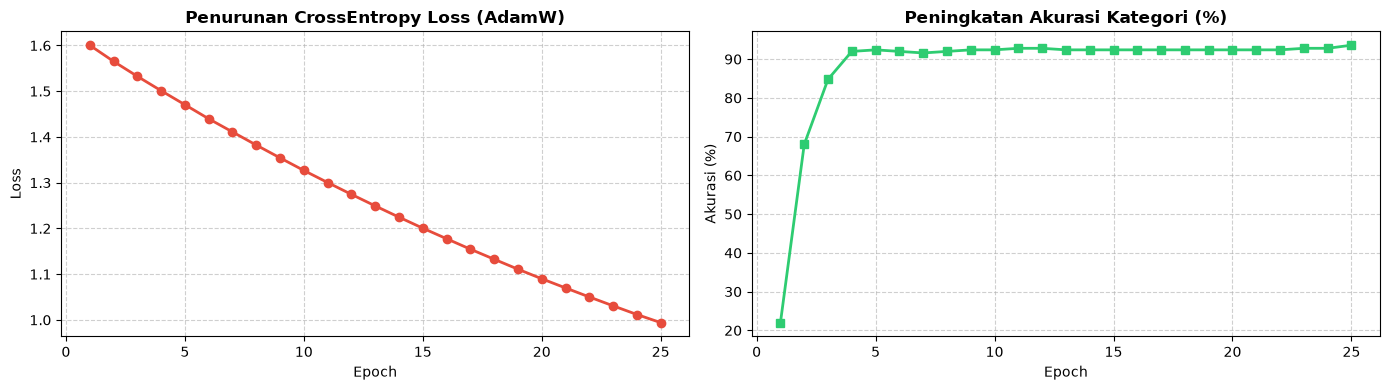

Grafik tersimpan di: experiment_results/sesi_augmented_svm\training_augmentation_curve.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot Loss
axes[0].plot(history['epoch'], history['loss'], color='#e74c3c', marker='o', linewidth=2)
axes[0].set_title('Penurunan CrossEntropy Loss (AdamW)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Accuracy
axes[1].plot(history['epoch'], history['acc'], color='#2ecc71', marker='s', linewidth=2)
axes[1].set_title('Peningkatan Akurasi Kategori (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi (%)')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plot_path = os.path.join(EXPERIMENT_DIR, "training_augmentation_curve.png")
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"Grafik tersimpan di: {plot_path}")